In [1]:
import os, sys, glob, io, contextlib, warnings
warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components, shortest_path
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)
import logging
logging.getLogger('harmonypy').setLevel(logging.ERROR)
logging.getLogger('harmonypy').propagate=False
logging.getLogger('harmonypy').disabled=True

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
# load processed manifold
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('malignant manifold:', adata.shape[0], 'cells')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_,s_,vt = np.linalg.svd(c, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor singular value): {s_[0]/s_[1]:.2f} (elongated -> linear geometry)')

malignant manifold: 1061 cells
UMAP principal-axis ratio (major/minor singular value): 3.12 (elongated -> linear geometry)


In [4]:
# re-score modules + graph-smooth for geography (raw kept for honest means)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('raw module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
print('smoothed spatial correlations (whole manifold):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a], adata.obs[b])[0,1]:+.2f}')

raw module means: {'Gast': -0.5067, 'pSom': -0.0681, 'Crest': 0.1493}
smoothed spatial correlations (whole manifold):
  Gast_sm vs pSom_sm: r = +0.97
  Crest_sm vs Gast_sm: r = -0.93
  Crest_sm vs pSom_sm: r = -0.94


In [5]:
# proliferation confound re-check on the loaded object (axis developmental, not cycling)
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
cyc = adata.obs['cell_cycle_phase'].astype(str)
print('cycling cells (G1/S|G2/M): %d / %d (%.1f%%)' % (int(cyc.isin(['G1/S','G2/M']).sum()),
      adata.n_obs, 100*cyc.isin(['G1/S','G2/M']).mean()))
for m in ['Gast_sm','pSom_sm','Crest_sm']:
    print(f'  corr(prolif, {m}) = {np.corrcoef(adata.obs["prolif_score"], adata.obs[m])[0,1]:+.2f}')
print('modules cell-cycle-decoupled -> whole manifold kept as the trajectory object')
sub = adata

cycling cells (G1/S|G2/M): 101 / 1061 (9.5%)
  corr(prolif, Gast_sm) = -0.09
  corr(prolif, pSom_sm) = -0.11
  corr(prolif, Crest_sm) = -0.04
modules cell-cycle-decoupled -> whole manifold kept as the trajectory object


In [6]:
# fit the cell-state manifold. Non-branching geometry (elongated; Gast/pSom overlap +
# Crest inverse gradient) -> scFates CURVE, not tree. Verify: 0 forks + a fold-free curve
# (self-approach ratio > 1) across Nodes; a PPT tree here yields a spurious fork.
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
for Nn in [15, 20, 30]:
    a2 = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(a2)
    print(f'curve N={Nn}: {tips} tips, {forks} forks | fold self-approach {sa:.2f}')
a3 = sub.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(a3, method='ppt', Nodes=200, ppt_lambda=2000, ppt_sigma=.5, use_rep='X_umap', seed=SEED, plot=False)
Bt = np.asarray(a3.uns['graph']['B'])
print(f'PPT tree(200): {int(((Bt>0).sum(0)==1).sum())} tips, {int(((Bt>0).sum(0)>=3).sum())} forks (spurious -> curve, not tree)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'chosen curve N=20: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'
print('confirmed: non-branching, fold-free curve')

curve N=15: 2 tips, 0 forks | fold self-approach 2.99
curve N=20: 2 tips, 0 forks | fold self-approach 2.98
curve N=30: 2 tips, 0 forks | fold self-approach 2.95
PPT tree(200): 3 tips, 1 forks (spurious -> curve, not tree)
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.98 (>1 = fold-free)
confirmed: non-branching, fold-free curve


In [7]:
# root at the DEVELOPMENTAL origin: Gast/pSom-high, Crest-low tip (Crest is late, not the root).
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f} '
          f'| Gast+pSom-Crest={info[tp][0]+info[tp][1]-info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))   # origin = max(Gast+pSom-Crest)
print(f'derived root = tip {root} (Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed modules):')
for s_ in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s_]); print(f'  {s_}: rho={rho:+.3f} p={p:.1e}')
tn = (t-t.min())/(t.max()-t.min())
for m,lab_ in [('Gast_sm','Gastrulation'),('pSom_sm','Somitogenesis'),('Crest_sm','Neural-crest')]:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')

tip 0: Gast=-0.3807 pSom=+0.0528 Crest=+0.0671 | Gast+pSom-Crest=-0.3950
tip 2: Gast=-0.5974 pSom=-0.1749 Crest=+0.2170 | Gast+pSom-Crest=-0.9893
derived root = tip 0 (Gast/pSom-high, Crest-low developmental origin)
gradient along pseudotime (Spearman rho on smoothed modules):
  Gast_sm: rho=-0.975 p=0.0e+00
  pSom_sm: rho=-0.979 p=0.0e+00
  Crest_sm: rho=+0.938 p=0.0e+00
Gastrulation-high decile mean pseudotime = 0.00
Somitogenesis-high decile mean pseudotime = 0.00
Neural-crest-high decile mean pseudotime = 0.98


In [8]:
# rename milestones by biological identity (origin vs terminus)
B = np.asarray(sub.uns['graph']['B']); tps = list(np.where((B>0).sum(0)==1)[0])
term = int([tp for tp in tps if tp != root][0])
scf.tl.rename_milestones(sub, new={str(root): 'Gast/pSom origin', str(term): 'Neural-crest terminus'})
print('milestones:', list(sub.obs['milestones'].cat.categories))

milestones: ['Gast/pSom origin', 'Neural-crest terminus']


In [9]:
# orientation consistency: pseudotime must agree with the stored house layout (binding)
t = sub.obs['t'].values
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
assert abs(r) > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
print(f'house orientation (X_umap_lin) reused from 01; corr(x_lin, pseudotime) = {r:+.2f} (origin left, terminus right)')

house orientation (X_umap_lin) reused from 01; corr(x_lin, pseudotime) = +0.99 (origin left, terminus right)


In [10]:
# sanitize non-serializable ElPiGraph entry, then save manifold
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
print('saved manifold.h5ad')

saved manifold.h5ad


saved manifold.pdf (curve edges overlaid; fold-free)


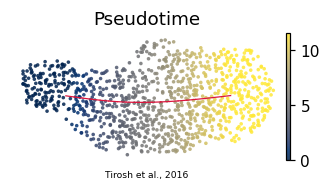

In [11]:
# save pseudotime manifold figure (house linear layout + curve edges overlaid to expose any fold)
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
# rotate the fitted node positions into the same linear frame for edge overlay
F = sub.uns['graph']['F'].T
xy = sub.obsm['X_umap']; cmean = xy.mean(0)
_,_,vt = np.linalg.svd(xy - cmean, full_matrices=False)
thr = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-thr), -np.sin(-thr)],[np.sin(-thr), np.cos(-thr)]])
Fr = (F - cmean) @ Rm.T
if (plot.obsm['X_umap'][:,0] * ((xy-cmean)@Rm.T)[:,0]).sum() < 0: Fr[:,0] = -Fr[:,0]  # match flip
Bm = np.asarray(sub.uns['graph']['B'])
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=22, alpha=.85, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ii,jj = np.where(np.triu(Bm>0))
for a,b in zip(ii,jj):
    ax.plot([Fr[a,0],Fr[b,0]],[Fr[a,1],Fr[b,1]], color='crimson', lw=.8, zorder=5)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.text(.5, -.13, 'Tirosh et al., 2016', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
plt.show()
print('saved manifold.pdf (curve edges overlaid; fold-free)')